# 01. Состояние продукта: аудитория, воронка, предложение

Смотрю на продукт с двух сторон маркетплейса:
- **спрос** — пользователи, которые ищут жилье (DAU/MAU, воронка поиск → просмотр → контакт, удержание);
- **предложение** — объявления (ликвидность: получает ли объявление контакты и как быстро).

Период: 1 июня – 31 августа 2025. Данные синтетические (см. `src/generate_data.py`), структура таблиц похожа на ту, что обычно лежит в DWH после агрегации сырых событий.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    "figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
DATA, FIG = "../data", "../reports/figures"

users = pd.read_parquet(f"{DATA}/users.parquet")
ud = pd.read_parquet(f"{DATA}/user_daily.parquet")
listings = pd.read_parquet(f"{DATA}/listings.parquet")
ld = pd.read_parquet(f"{DATA}/listing_daily.parquet")

for df in (ud, ld):
    df["dt"] = pd.to_datetime(df["dt"])
users["reg_date"] = pd.to_datetime(users["reg_date"])
for c in ("created_dt", "closed_dt"):
    listings[c] = pd.to_datetime(listings[c])

print(f"user_daily: {ud.shape}, listing_daily: {ld.shape}")
ud.head()

user_daily: (701078, 8), listing_daily: (507023, 5)


,dt,user_id,platform,sessions,searches,listing_views,favorites,contacts
0,2025-06-01,44,android,1,0,3,0,0
1,2025-06-01,75,web,1,1,5,0,0
2,2025-06-01,123,android,1,5,4,0,0
3,2025-06-01,187,ios,2,6,1,0,1
4,2025-06-01,207,ios,1,2,4,0,0


## 1. Аудитория: DAU / WAU / MAU и stickiness

,DAU,WAU,MAU,stickiness
2025-06-01,5133.867,17360.667,35982.000,0.189
2025-07-01,7886.161,24946.516,44621.871,0.177
2025-08-01,9761.000,30219.968,54670.161,0.178


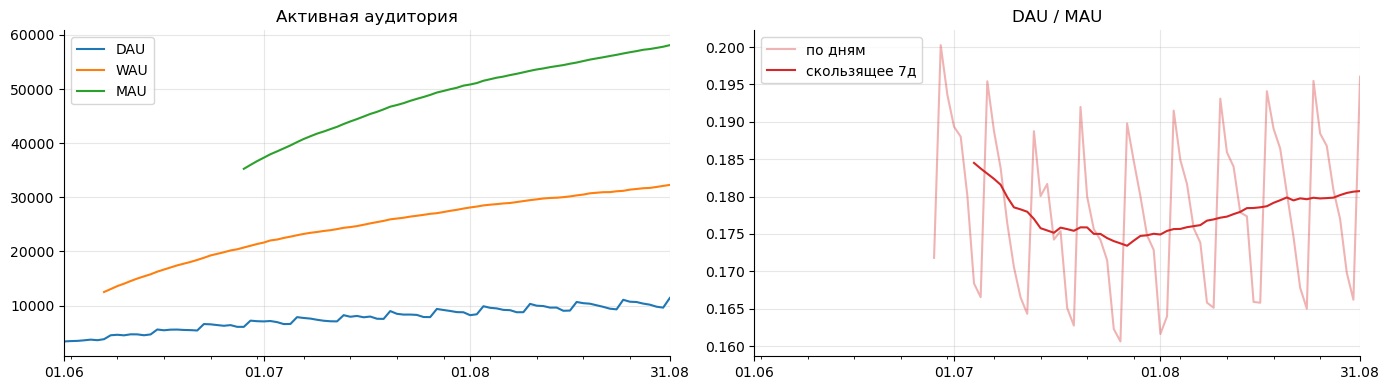

In [2]:
def rolling_unique(df, window):
    days = np.sort(df["dt"].unique())
    res = {}
    for d in days:
        mask = (df["dt"] > d - pd.Timedelta(days=window)) & (df["dt"] <= d)
        res[d] = df.loc[mask, "user_id"].nunique()
    return pd.Series(res)

dau = ud.groupby("dt")["user_id"].nunique()
wau = rolling_unique(ud, 7)
mau = rolling_unique(ud, 28)

aud = pd.DataFrame({"DAU": dau, "WAU": wau, "MAU": mau})
aud["stickiness"] = aud["DAU"] / aud["MAU"]
# в начале периода окна неполные — не показываем
start = aud.index.min()
aud.loc[aud.index < start + pd.Timedelta(days=6), "WAU"] = np.nan
aud.loc[aud.index < start + pd.Timedelta(days=27), ["MAU", "stickiness"]] = np.nan

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
aud[["DAU", "WAU", "MAU"]].plot(ax=ax[0])
ax[0].set_title("Активная аудитория")
aud["stickiness"].plot(ax=ax[1], color="C3", alpha=0.35, label="по дням")
aud["stickiness"].rolling(7).mean().plot(ax=ax[1], color="C3", label="скользящее 7д")
ax[1].legend()
ax[1].set_title("DAU / MAU")
for a in ax:
    a.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
plt.tight_layout()
plt.savefig(f"{FIG}/01_audience.png", dpi=120)
aud.resample("MS").mean().round(3)

In [3]:
# как DAU распределен по дням недели (относительно среднего за неделю)
tmp = dau.to_frame("dau")
tmp["week"] = tmp.index.to_period("W")
tmp["dow"] = tmp.index.dayofweek
tmp["rel"] = tmp["dau"] / tmp.groupby("week")["dau"].transform("mean")
full_weeks = tmp.groupby("week")["dow"].transform("count") == 7
tmp[full_weeks].groupby("dow")["rel"].mean().rename(index=dict(enumerate(["пн", "вт", "ср", "чт", "пт", "сб", "вс"]))).round(3)

dow
пн    1.006
вт    1.000
ср    0.989
чт    0.984
пт    0.945
сб    0.949
вс    1.127
Name: rel, dtype: float64

Аудитория за лето растет: DAU ~5.1k в июне → ~9.8k в августе (приток новых пользователей + сезон аренды перед учебным годом). DAU/MAU держится около 0.18 — для сервиса, куда приходят под конкретную задачу, это нормально.

Есть недельная сезонность: провал в пятницу-субботу, пик в воскресенье (+13% к среднему за неделю). Для экспериментов это значит, что длительность теста лучше брать кратной неделе.

## 2. Воронка: поиск → просмотр объявления → контакт

In [4]:
ud["has_search"] = ud["searches"] > 0
ud["has_view"] = ud["listing_views"] > 0
ud["has_contact"] = ud["contacts"] > 0

funnel = ud.groupby("platform")[["has_search", "has_view", "has_contact"]].mean()
sums = ud.groupby("platform")[["contacts", "listing_views"]].sum()
funnel["contacts_per_view"] = sums["contacts"] / sums["listing_views"]
funnel["views_per_user_day"] = ud.groupby("platform")["listing_views"].mean()
funnel.loc["всего"] = [*ud[["has_search", "has_view", "has_contact"]].mean(),
                       ud["contacts"].sum() / ud["listing_views"].sum(),
                       ud["listing_views"].mean()]
funnel.round(3)

,has_search,has_view,has_contact,contacts_per_view,views_per_user_day
platform,,,,,
android,0.935,0.960,0.270,0.065,5.957
ios,0.934,0.965,0.304,0.071,6.440
web,0.935,0.944,0.213,0.059,4.726
всего,0.935,0.957,0.264,0.065,5.759


In [5]:
by_role = ud.merge(users[["user_id", "role"]], on="user_id").groupby("role").agg(
    user_days=("user_id", "size"),
    users=("user_id", "nunique"),
    views=("listing_views", "sum"),
    contacts=("contacts", "sum"),
)
by_role["share_of_contacts"] = by_role["contacts"] / by_role["contacts"].sum()
by_role["contacts_per_view"] = by_role["contacts"] / by_role["views"]
by_role["days_per_user"] = by_role["user_days"] / by_role["users"]
by_role.sort_values("contacts", ascending=False).round(3)

,user_days,users,views,contacts,share_of_contacts,contacts_per_view,days_per_user
role,,,,,,,
renter,237662,42949,1369154,116220,0.442,0.085,5.534
buyer,203454,36981,1170526,73293,0.279,0.063,5.502
seller,114925,14977,661384,41767,0.159,0.063,7.673
agent,145037,7233,836257,31774,0.121,0.038,20.052


In [6]:
# насколько активность сконцентрирована: какую долю просмотров дают топ-N% пользователей
per_user = ud.groupby("user_id")["listing_views"].sum().sort_values(ascending=False)
cum = per_user.cumsum() / per_user.sum()
for q in (0.01, 0.05, 0.1, 0.2):
    print(f"топ {q:.0%} пользователей -> {cum.iloc[int(len(cum) * q) - 1]:.1%} просмотров")

топ 1% пользователей -> 8.8% просмотров
топ 5% пользователей -> 28.7% просмотров
топ 10% пользователей -> 43.6% просмотров
топ 20% пользователей -> 62.4% просмотров


- Конверсия из просмотра в контакт ~6.5%. Лучше всего на iOS (7.1%), хуже всего на вебе (5.9%), и на вебе еще и меньше просмотров на пользователя — доля дней с контактом 21% против 30% на iOS. Веб выглядит как точка роста, стоит посмотреть, чем отличается карточка объявления на вебе.
- Арендаторы конвертируются в контакт заметно лучше покупателей (8.5% vs 6.3%) — цикл решения короче.
- Агенты — ~7% пользователей, но заходят в среднем 20 дней из 92 и дают 12% контактов. Топ-10% пользователей дают 44% просмотров. Для экспериментов это значит, что поюзерные метрики будут с тяжелым хвостом и большой дисперсией → нужны методы снижения дисперсии (CUPED) и аккуратная работа с ratio-метриками.

## 3. Удержание новых пользователей

Когорта = неделя первой активности, считаю только пользователей, зарегистрированных в период наблюдения (иначе в когорты попадут "старички", которые просто впервые зашли летом).

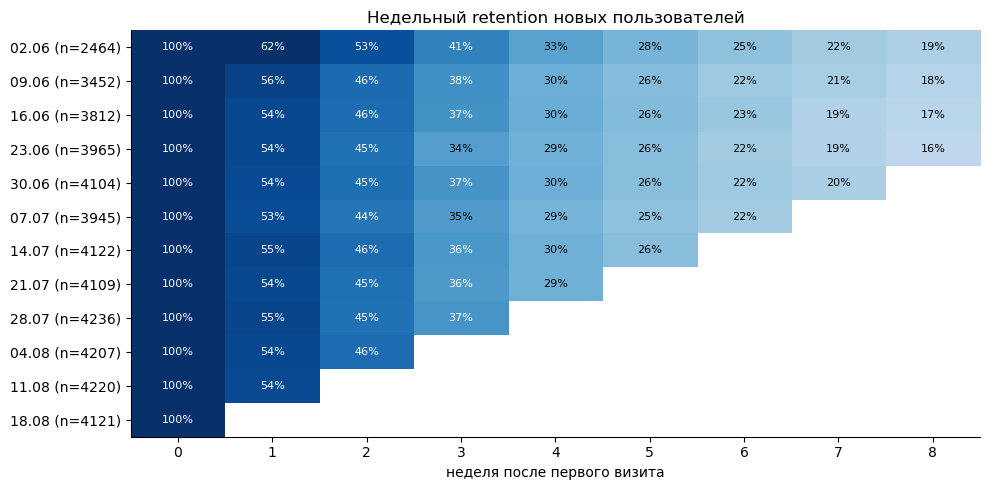

In [7]:
new_users = users.loc[users["reg_date"] >= "2025-06-01", "user_id"]
nu = ud[ud["user_id"].isin(new_users)].copy()
first = nu.groupby("user_id")["dt"].min().rename("first_dt")
nu = nu.join(first, on="user_id")
nu["cohort"] = nu["first_dt"].dt.to_period("W").dt.start_time
nu["week_n"] = (nu["dt"] - nu["first_dt"]).dt.days // 7

cohort_size = nu.groupby("cohort")["user_id"].nunique()
ret = nu.groupby(["cohort", "week_n"])["user_id"].nunique().unstack()
ret = ret.div(cohort_size, axis=0)
# первая когорта неполная (неделя начинается в мае), последняя — без данных о возвратах
ret = ret.iloc[1:-1]
cohort_size = cohort_size.loc[ret.index]

# отрезаем недели, которые для когорты еще не наступили полностью
last_day = ud["dt"].max()
for c in ret.index:
    max_week = (last_day - c).days // 7 - 1
    ret.loc[c, ret.columns > max_week] = np.nan

ret = ret.loc[:, :8]
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(ret.values, cmap="Blues", aspect="auto", vmin=0, vmax=0.6)
ax.set_xticks(range(ret.shape[1]))
ax.set_yticks(range(ret.shape[0]))
ax.set_yticklabels([f"{c:%d.%m} (n={cohort_size[c]})" for c in ret.index])
ax.set_xlabel("неделя после первого визита")
ax.grid(False)
for i in range(ret.shape[0]):
    for j in range(ret.shape[1]):
        v = ret.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.35 else "black")
ax.set_title("Недельный retention новых пользователей")
plt.tight_layout()
plt.savefig(f"{FIG}/01_retention.png", dpi=120)

In [8]:
# средняя кривая удержания, взвешенная по размеру когорты
w = ret.notna().mul(cohort_size, axis=0)
curve = (ret.fillna(0) * w).sum() / w.sum()
curve.round(3)

week_n
0    1.000
1    0.548
2    0.458
3    0.364
4    0.298
5    0.260
6    0.226
7    0.200
8    0.177
dtype: float64

На следующей неделе возвращается ~55%, к 4-й неделе ~30%, к 8-й ~18%. Когорты между собой почти не отличаются, т.е. за лето ничего не сломалось и не улучшилось.

Продукт "по задаче": человек ищет квартиру несколько недель, потом уходит, и это нормально. Поэтому классический retention здесь не главная метрика здоровья продукта. Полезнее смотреть, **решил ли пользователь свою задачу** (дошел до контакта) и сколько времени на это ушло. А вот тех, кто ушел без единого контакта, стоит пытаться вернуть — гипотеза для discovery: сохраненные поиски и пуши по новым объявлениям.

## 4. Предложение: ликвидность объявлений

In [9]:
# первые 7 дней жизни объявления; берем только объявления, опубликованные внутри периода
lst = listings[(listings["created_dt"] >= "2025-06-01") & (listings["created_dt"] <= "2025-08-24")].copy()
first7 = ld.merge(lst[["listing_id", "created_dt"]], on="listing_id")
first7 = first7[(first7["dt"] - first7["created_dt"]).dt.days < 7]
agg7 = first7.groupby("listing_id")[["views", "contacts"]].sum()
lst = lst.join(agg7, on="listing_id").fillna({"views": 0, "contacts": 0})
lst["liquid_7d"] = lst["contacts"] > 0

lst.pivot_table(index="city", columns="deal_type", values="liquid_7d", aggfunc="mean").round(3)

deal_type,rent,sale
city,,
Актобе,0.867,0.823
Алматы,0.886,0.826
Астана,0.887,0.819
Атырау,0.873,0.814
Караганда,0.900,0.796
Шымкент,0.886,0.816


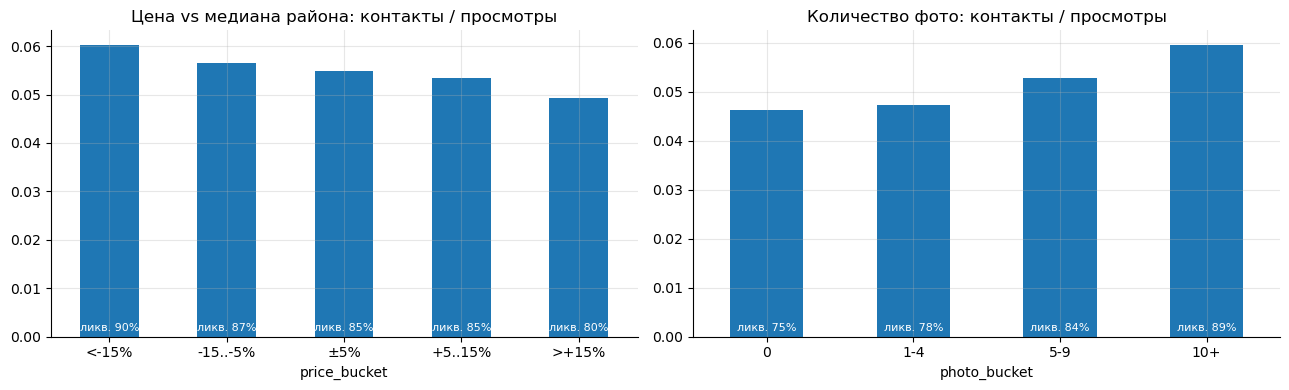

In [10]:
# цена за м2 относительно медианы района (внутри типа сделки)
lst["price_m2"] = lst["price_kzt"] / lst["area_m2"]
lst["price_vs_district"] = lst["price_m2"] / lst.groupby(["city", "district", "deal_type"])["price_m2"].transform("median")
lst["price_bucket"] = pd.cut(lst["price_vs_district"], [0, 0.85, 0.95, 1.05, 1.15, 10],
                             labels=["<-15%", "-15..-5%", "±5%", "+5..15%", ">+15%"])
lst["photo_bucket"] = pd.cut(lst["photos_cnt"], [-1, 0, 4, 9, 30], labels=["0", "1-4", "5-9", "10+"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, col, title in [(ax[0], "price_bucket", "Цена vs медиана района"),
                      (ax[1], "photo_bucket", "Количество фото")]:
    g = lst.groupby(col, observed=True).agg(cr=("contacts", "sum"), v=("views", "sum"), liq=("liquid_7d", "mean"))
    (g["cr"] / g["v"]).plot.bar(ax=a, color="C0", rot=0)
    a.set_title(f"{title}: контакты / просмотры")
    for i, v in enumerate(g["liq"]):
        a.annotate(f"ликв. {v:.0%}", (i, 0), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8, color="white")
plt.tight_layout()
plt.savefig(f"{FIG}/01_listing_quality.png", dpi=120)

- За первую неделю контакт получают 82-90% объявлений, аренда ликвиднее продажи во всех городах.
- Объявления дороже рынка района хуже конвертируются в контакт (4.9% у тех, кто дороже медианы на 15%+, против 6.0% у дешевых). Это кандидат на фичу "оценка цены" для продавца при подаче/редактировании объявления — проверяется экспериментом на стороне предложения.
- Объявления без фото: CR 4.6% против 6.0% у объявлений с 10+ фото, ликвидность 75% против 89%. Можно жестче подталкивать добавлять фото на шаге подачи.

Оговорка: это корреляции. Дешевые объявления с большим количеством фото могут отличаться еще чем-то (например, их чаще подают агенты), поэтому здесь это только источник гипотез.

## Итоги и гипотезы

| что увидели | гипотеза | как проверить |
|---|---|---|
| Конверсия просмотр → контакт ~6.5%, на вебе ниже | улучшенная карточка объявления (галерея, кнопка звонка на первом экране) поднимет CR | A/B тест, ноутбук 02 |
| К 4-й неделе возвращается ~30% новых пользователей | сохраненные поиски + пуши вернут тех, кто ушел без контакта | A/B на новых пользователях, метрика — доля дошедших до контакта за 30 дней |
| Дорогие относительно района объявления плохо конвертируются | подсказка продавцу о рыночной цене снизит долю "мертвых" объявлений | эксперимент на продавцах, кластеризация по районам |
| Владельцы покупают продвижение | нужно понимать реальный эффект платных услуг | causal inference на наблюдательных данных, ноутбук 03 |